In [1]:
!mamba install scikit-learn pandas


mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, scikit-learn, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.583 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ pandas              3.1.0       np23py313h124dbc7_0  emscripten-forge-4x
+ pysocks             1.7.1       py313h1804a44_3      emscripten-forge-4x
+ request

In [2]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score,
    learning_curve
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
df = pd.read_csv("../Data/Telco-Customer-Churn.csv")

# Clean dataset
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df = df.drop(columns=["customerID"])

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Identify column types
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include="object").columns

print("Dataset shape:", df.shape)
print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))


/tmp/xpython_42/779615928.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns


Dataset shape: (7043, 20)
Numerical features: 4
Categorical features: 15


In [4]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=67,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Preprocessing completed!")


Training shape: (5282, 19)
Testing shape: (1761, 19)
Preprocessing completed!


In [5]:
models = {
    "Decision Tree": {
        "model": DecisionTreeClassifier(random_state=42),
        "params": {
            "classifier__max_depth": [3, 5, 7, 10],
            "classifier__min_samples_split": [2, 5, 10]
        }
    },

    "Random Forest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "classifier__n_estimators": [50, 100],
            "classifier__max_depth": [5, 10, None]
        }
    },

    "SVM": {
        "model": SVC(),
        "params": {
            "classifier__C": [0.1, 1, 10],
            "classifier__kernel": ["linear", "rbf"]
        }
    }
}

print("Models and parameter grids defined successfully!")


Models and parameter grids defined successfully!


In [6]:
best_models = {}
tuning_results = []

for name, config in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", config["model"])
    ])

    grid = GridSearchCV(
        pipeline,
        config["params"],
        cv=3,
        scoring="recall",
        n_jobs=1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best Parameters": grid.best_params_,
        "Best CV Recall": grid.best_score_
    })

    print(name, "tuning completed!")
    

Decision Tree tuning completed!
Random Forest tuning completed!
SVM tuning completed!


In [7]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df["Best CV Recall"] = tuning_df["Best CV Recall"].round(4)

tuning_df


,Model,Best Parameters,Best CV Recall
0,Decision Tree,"{'classifier__max_depth': 5, 'classifier__min_...",0.5614
1,Random Forest,"{'classifier__max_depth': 10, 'classifier__n_e...",0.5250
2,SVM,"{'classifier__C': 1, 'classifier__kernel': 'li...",0.5442


In [8]:
bias_variance_results = []

for name, model in best_models.items():

    train_score = model.score(X_train, y_train)

    cv_score = cross_val_score(
        model,
        X_train,
        y_train,
        cv=3,
        scoring="recall",
        n_jobs=1
    ).mean()

    bias_variance_results.append({
        "Model": name,
        "Training Accuracy": train_score,
        "Validation Recall": cv_score
    })

bias_df = pd.DataFrame(bias_variance_results)

bias_df.round(4)


,Model,Training Accuracy,Validation Recall
0,Decision Tree,0.8054,0.5614
1,Random Forest,0.8809,0.5250
2,SVM,0.8012,0.5442


In [9]:
bias_df.round(4)


,Model,Training Accuracy,Validation Recall
0,Decision Tree,0.8054,0.5614
1,Random Forest,0.8809,0.5250
2,SVM,0.8012,0.5442


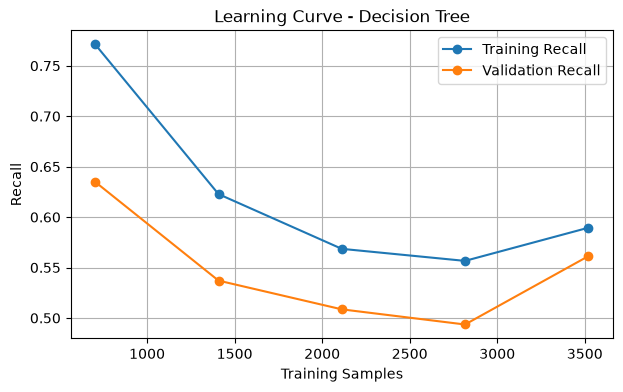

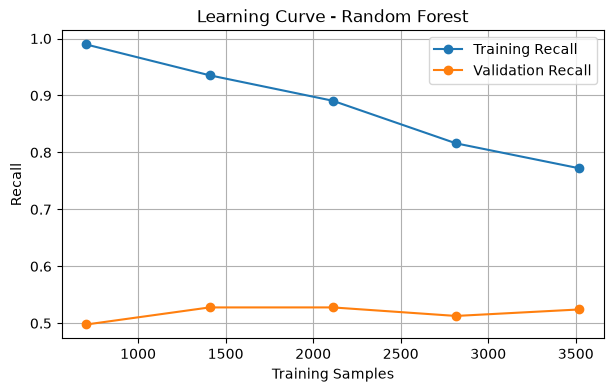

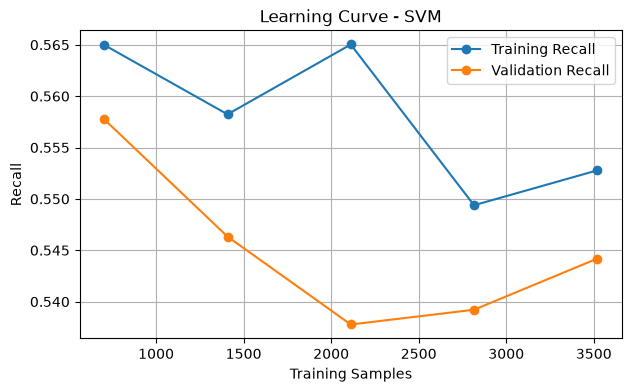

In [10]:
from sklearn.model_selection import learning_curve

for name, model in best_models.items():

    train_sizes, train_scores, val_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=3,
        scoring="recall",
        train_sizes=np.linspace(0.2, 1.0, 5),
        n_jobs=1
    )

    plt.figure(figsize=(7, 4))

    plt.plot(
        train_sizes,
        train_scores.mean(axis=1),
        marker="o",
        label="Training Recall"
    )

    plt.plot(
        train_sizes,
        val_scores.mean(axis=1),
        marker="o",
        label="Validation Recall"
    )

    plt.title(f"Learning Curve - {name}")
    plt.xlabel("Training Samples")
    plt.ylabel("Recall")
    plt.legend()
    plt.grid()
    plt.show()
    

In [11]:
final_results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)

    if name == "SVM":
        y_score = model.decision_function(X_test)
    else:
        y_score = model.predict_proba(X_test)[:, 1]

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    })

final_df = pd.DataFrame(final_results)

final_df = final_df.sort_values(
    by=["Recall", "ROC-AUC"],
    ascending=False
)

final_df.round(4)


,Model,Accuracy,Precision,Recall,ROC-AUC
1,Random Forest,0.8012,0.6459,0.5546,0.8296
2,SVM,0.7910,0.6241,0.5332,0.8278
0,Decision Tree,0.7825,0.6050,0.5182,0.8195


In [12]:
final_df.round(4)


,Model,Accuracy,Precision,Recall,ROC-AUC
1,Random Forest,0.8012,0.6459,0.5546,0.8296
2,SVM,0.7910,0.6241,0.5332,0.8278
0,Decision Tree,0.7825,0.6050,0.5182,0.8195


In [13]:
champion_name = final_df.iloc[0]["Model"]

champion_model = best_models[champion_name]

joblib.dump(
    champion_model,
    "../models/churn_v3.joblib"
)

print("Day 3 Champion:", champion_name)
print("Model saved successfully!")


Day 3 Champion: Random Forest
Model saved successfully!


In [14]:
import os

print(os.path.exists("../models/churn_v3.joblib"))


True
